## Übung 02 – Musterlösung

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

In [14]:
# Dieser Block ist nur hoer, damit ci die Plots für das Skript exzportieren kann.
# Uncomment 
from pathlib import Path

# Verzeichnis für exportierte Abbildungen und Videos
notebook_name = "Uebung02"
project_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents) if (path / ".git").exists()),
    Path.cwd(),
)
output_dir = project_root / "data" / "01_mechanik" / notebook_name
output_dir.mkdir(parents=True, exist_ok=True)

# Abbildungsstil für ein A4-Skript
latex_textwidth_in = 6.3
single_panel_width = 0.5 * latex_textwidth_in
single_panel_square = (single_panel_width, single_panel_width)
single_panel_wide = (single_panel_width, 0.68 * single_panel_width)
full_width_three_panel = (latex_textwidth_in, 0.36 * latex_textwidth_in)
animation_display_width = 360

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman", "CMU Serif", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "font.size": 10,
    "axes.titlesize": 10,
    "axes.labelsize": 10,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "legend.fontsize": 8.5,
    "lines.linewidth": 1.2,
    "axes.linewidth": 0.8,
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.03,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
})

print(f"Output directory: {output_dir}")

Output directory: /Users/meckstei/Documents/Physik/Lehre/Vorlesungen/WS26_27/CIS_2627/cis-compphys2627/data/01_mechanik/Uebung02


### Teil 1 – Zwei gekoppelte Pendel

Wir betrachten zwei gekoppelte Pendel. Die Auslenkungen werden durch $x_1$ und $x_2$ beschrieben. Die kinetische und die potentielle Energie seien

$$T=\frac12m_1\dot x_1^2+\frac12m_2\dot x_2^2,$$

$$V=\frac12\left[k_1x_1^2+k_2x_2^2+k_{12}(x_1-x_2)^2\right].$$

Dabei beschreiben $k_1$ und $k_2$ die Rückstellkräfte der einzelnen Pendel; $k_{12}$ beschreibt die Kopplung.

### 1a) Hamiltonfunktion und Bewegungsgleichungen

Wie sieht eine Realisierung des Systems mit zwei Massen und Federn aus?

Bestimmen Sie die kanonischen Impulse $p_1$ und $p_2$. Stellen Sie anschließend die Hamiltonfunktion

$$H(x_1,x_2,p_1,p_2)$$

auf und leiten Sie alle vier Hamilton-Gleichungen her.

**Rechnung:**

Eine mögliche Realisierung besteht aus zwei Massen, die sich entlang einer Geraden bewegen. Jede Masse ist durch eine Feder mit einer festen Wand verbunden; eine dritte Feder mit Federkonstante $k_{12}$ verbindet die beiden Massen.

Aus der Lagrangefunktion $L=T-V$ folgen die kanonischen Impulse

$$p_1=\frac{\partial L}{\partial\dot x_1}=m_1\dot x_1,\qquad p_2=m_2\dot x_2.$$

Damit lautet die Hamiltonfunktion

$$H=\frac{p_1^2}{2m_1}+\frac{p_2^2}{2m_2}+\frac12\left[k_1x_1^2+k_2x_2^2+k_{12}(x_1-x_2)^2\right].$$

Die Hamilton-Gleichungen sind

$$\dot x_1=\frac{p_1}{m_1},\qquad \dot x_2=\frac{p_2}{m_2},$$

$$\dot p_1=-(k_1+k_{12})x_1+k_{12}x_2,$$

$$\dot p_2=k_{12}x_1-(k_2+k_{12})x_2.$$

### 1b) Skalierte kanonische Variablen

Betrachten Sie zunächst einen einzelnen Oszillator mit Masse $m$, Koordinate $x$ und Impuls $p$. Wir führen den neuen Impuls

$$P=\frac{p}{\sqrt m}$$

ein. Wie muss die neue Koordinate $Q$ gewählt werden, damit die Transformation kanonisch beziehungsweise symplektisch ist? **Hinweis:** Eine kanonische Transformation erhält die orientierte Fläche im Phasenraum. 

Schreiben Sie danach die Hamiltonfunktion in den Variablen $(Q,P)$ und vergewissern Sie sich, dass die Bewegungsgleichungen weiterhin die kanonische Form 

$$\dot P=-\frac{\partial H}{\partial Q},\qquad \dot Q=\frac{\partial H}{\partial P}.$$

**Rechnung:**

Wegen $dP=dp/\sqrt m$ muss $dQ=\sqrt m\,dx$ gelten. Bis auf eine additive Konstante ist daher

$$Q=\sqrt m\,x.$$

Dann gilt tatsächlich $dP\,dQ=dp\,dx$. Für

$$H=\frac{p^2}{2m}+\frac{kx^2}{2}$$

erhält man mit $p=\sqrt m\,P$ und $x=Q/\sqrt m$

$$H=\frac{P^2}{2}+\frac{k}{2m}Q^2=\frac12\left(P^2+\omega^2Q^2\right),\qquad \omega^2=\frac{k}{m}.$$

Die Hamilton-Gleichungen behalten ihre kanonische Form:

$$\dot Q=\frac{\partial H}{\partial P}=P,\qquad \dot P=-\frac{\partial H}{\partial Q}=-\frac{k}{m}Q.$$

### 1c) Gekoppeltes System in den neuen Variablen

Verwenden Sie für die gekoppelten Pendel eine analoge Transformation

$$P_i=\frac{p_i}{\sqrt{m_i}},\qquad Q_i=\cdots.$$

Schreiben Sie die Hamiltonfunktion des gekoppelten Systems in den Variablen $(Q_1,Q_2,P_1,P_2)$ und leiten Sie daraus die vier Bewegungsgleichungen ab.

**Rechnung:**

Einsetzen von $p_i=\sqrt{m_i}P_i$ und $x_i=Q_i/\sqrt{m_i}$ ergibt

$$H=\frac12(P_1^2+P_2^2)+\frac12\left[\frac{k_1}{m_1}Q_1^2+\frac{k_2}{m_2}Q_2^2+k_{12}\left(\frac{Q_1}{\sqrt{m_1}}-\frac{Q_2}{\sqrt{m_2}}\right)^2\right].$$

Daraus folgen

$$\dot Q_1=P_1,\qquad \dot Q_2=P_2,$$

$$\dot P_1=-\frac{k_1+k_{12}}{m_1}Q_1+\frac{k_{12}}{\sqrt{m_1m_2}}Q_2,$$

$$\dot P_2=\frac{k_{12}}{\sqrt{m_1m_2}}Q_1-\frac{k_2+k_{12}}{m_2}Q_2.$$

### 1d) Numerische Untersuchung

In der Vorlesung werden wir ausgehend von der Form aus c) die Bewegungsgleichungen analytisch weiterbehandeln. Lösen Sie hier die Gleichungen numerisch, um ein Bild von der Physik zu bekommen:

Setzen Sie

$$m_1=m_2=1,\qquad k_1=k_2=1$$

und lösen Sie die Bewegungsgleichungen numerisch für verschiedene Kopplungsstärken $k_{12}$. Verwenden Sie zunächst

$$Q_1(0)=1,\quad Q_2(0)=0,\quad P_1(0)=P_2(0)=0$$

sowie $k_{12}=0;\,0{,}05;\,0{,}5;\,2$. Stellen Sie $Q_1(t)$ und $Q_2(t)$ dar und beschreiben Sie, wie sich die Bewegung mit der Kopplung verändert.

Vervollständigen Sie dazu die rechte Seite der Differentialgleichung. Die übrige Simulations- und Plot-Infrastruktur ist vorgegeben.

In [15]:
def coupled_rhs(t, state, m1, m2, k1, k2, k12):
    Q1, Q2, P1, P2 = state
    dQ1 = P1
    dQ2 = P2
    dP1 = -(k1 + k12)/m1*Q1 + k12/np.sqrt(m1*m2)*Q2
    dP2 = k12/np.sqrt(m1*m2)*Q1 - (k2 + k12)/m2*Q2
    return np.array([dQ1, dQ2, dP1, dP2])

m1 = m2 = 1.0
k1 = k2 = 1.0
initial_state = np.array([1.0, 0.0, 0.0, 0.0])
couplings = [0.0, 0.05, 0.1, 0.5]
t_eval = np.linspace(0.0, 160.0, 4001)

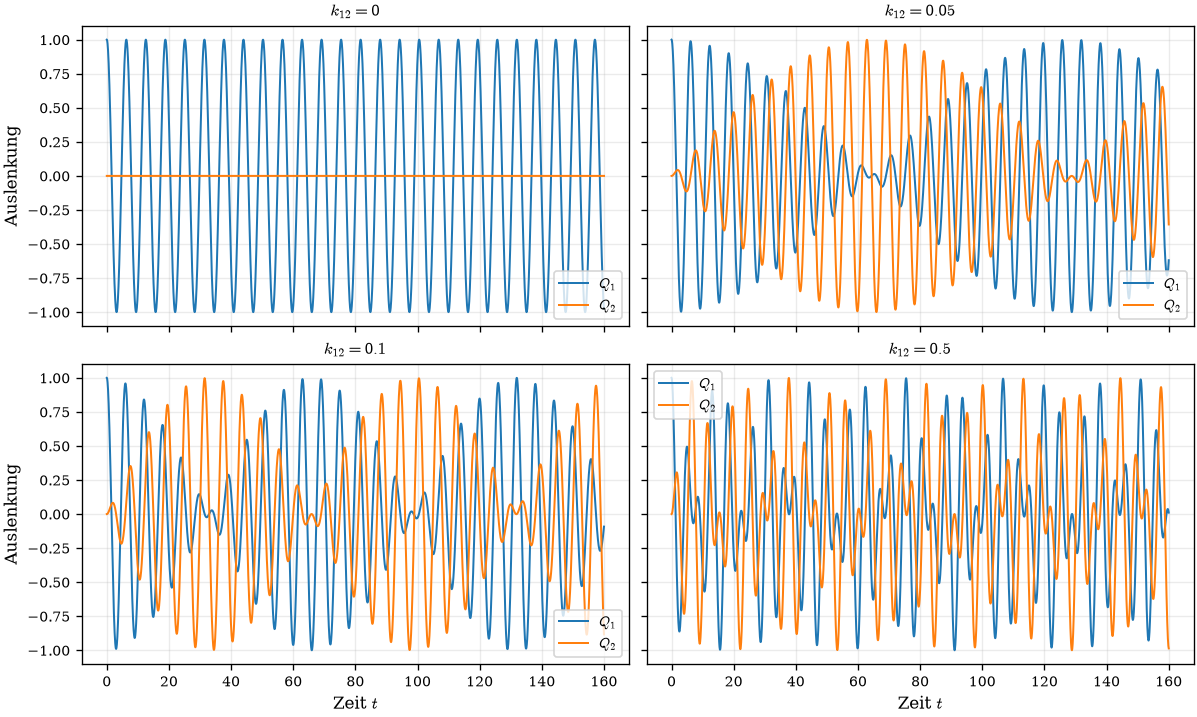

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


In [16]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey=True,
                         constrained_layout=True)

solutions = {}
for ax, k12 in zip(axes.flat, couplings):
    solution = solve_ivp(
        coupled_rhs, (t_eval[0], t_eval[-1]), initial_state, t_eval=t_eval,
        args=(m1, m2, k1, k2, k12), rtol=1e-10, atol=1e-12,
    )
    solutions[k12] = solution
    ax.plot(solution.t, solution.y[0], label="$Q_1$")
    ax.plot(solution.t, solution.y[1], label="$Q_2$")
    ax.set_title(rf"$k_{{12}}={k12:g}$")
    ax.grid(alpha=0.25)
    ax.legend()

for ax in axes[-1, :]:
    ax.set_xlabel("Zeit $t$")
for ax in axes[:, 0]:
    ax.set_ylabel("Auslenkung")
plt.show()
fig.savefig(output_dir / "exercise02_pendulum_01.pdf")

**Beobachtungen:**

Ohne Kopplung bleibt das zweite Pendel in Ruhe. Für $k_{12}>0$ wird die Schwingung zwischen beiden Pendeln übertragen: Die Amplitude von $Q_1$ nimmt ab, während die von $Q_2$ zunimmt, und später kehrt sich der Vorgang um. Es entstehen Schwebungen. Bei schwacher Kopplung erfolgt dieser Austausch langsam; mit wachsendem $k_{12}$ wird die zweite charakteristische Frequenz größer und die Struktur der Schwebung verändert sich.

Wiederholen Sie den Versuch außerdem für die beiden Anfangsbedingungen

$$Q_1(0)=Q_2(0)=1,\qquad P_1(0)=P_2(0)=0$$

und

$$Q_1(0)=1,\quad Q_2(0)=-1,\qquad P_1(0)=P_2(0)=0.$$

Was ist an diesen beiden Bewegungen besonders?

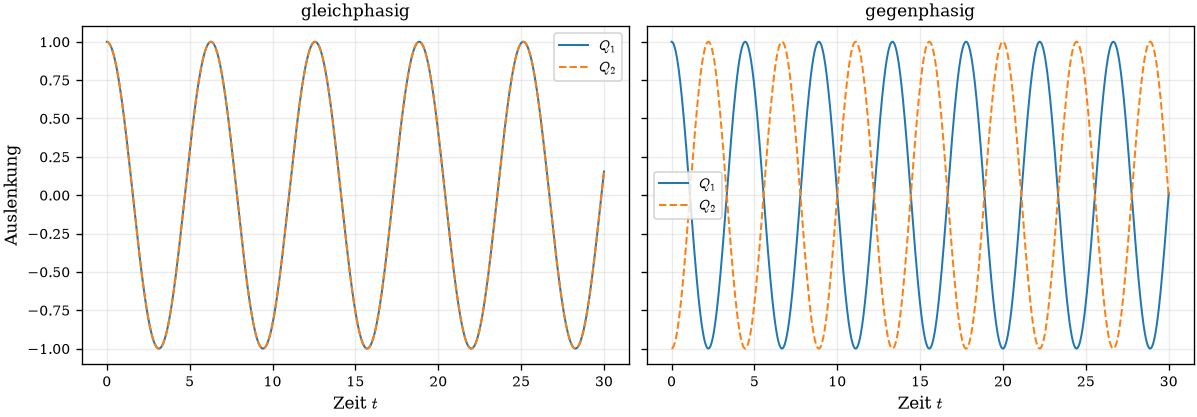

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


In [17]:
k12_modes = 0.5
mode_states = {
    "gleichphasig": np.array([1.0, 1.0, 0.0, 0.0]),
    "gegenphasig": np.array([1.0, -1.0, 0.0, 0.0]),
}

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True,
                         constrained_layout=True)
for ax, (name, state0) in zip(axes, mode_states.items()):
    solution = solve_ivp(
        coupled_rhs, (0.0, 30.0), state0, t_eval=np.linspace(0, 30, 1501),
        args=(m1, m2, k1, k2, k12_modes), rtol=1e-10, atol=1e-12,
    )
    ax.plot(solution.t, solution.y[0], label="$Q_1$")
    ax.plot(solution.t, solution.y[1], "--", label="$Q_2$")
    ax.set(title=name, xlabel="Zeit $t$")
    ax.grid(alpha=0.25)
    ax.legend()
axes[0].set_ylabel("Auslenkung")
plt.show()
fig.savefig(output_dir / "exercise02_pendulum_02.pdf")

Bei den beiden speziellen Anfangsbedingungen tritt keine Schwebung auf. Sie regen jeweils genau eine Normalschwingung an.

Für die gleichphasige Bewegung gilt $Q_1=Q_2$; die Kopplung wird nicht gedehnt und die Frequenz ist $\omega_+=1$. Für die gegenphasige Bewegung gilt $Q_1=-Q_2$; die Kopplung wirkt maximal und die Frequenz ist

$$\omega_-=\sqrt{1+2k_{12}}.$$

Die Anfangsbedingung $(Q_1,Q_2)=(1,0)$ ist eine Überlagerung dieser beiden Normalschwingungen. Ihre unterschiedlichen Frequenzen erzeugen die beobachtete Schwebung.

### Teil 2 – Eine symplektische Mittelpunktregel

Wir betrachten nun den harmonischen Oszillator

$$H(q,p)=\frac12(q^2+p^2),\qquad \dot q=p,\quad \dot p=-q.$$

Die exakte Bewegung ist eine Rotation im Phasenraum. Damit bleiben sowohl die Energie als auch die Phasenraumfläche erhalten.

### 2a) Explizite Mittelpunktregel

Für eine Differentialgleichung $\dot{\boldsymbol y}=f(\boldsymbol y)$ lautet die explizite Mittelpunktregel

$$\boldsymbol y_{n+1/2}^{*}=\boldsymbol y_n+\frac h2f(\boldsymbol y_n),$$

$$\boldsymbol y_{n+1}=\boldsymbol y_n+h f(\boldsymbol y_{n+1/2}^{*}).$$

Leiten Sie für den harmonischen Oszillator die Update-Matrix $M_{\mathrm{expl}}$ mit

$$\begin{pmatrix}q_{n+1}\\p_{n+1}\end{pmatrix}=M_{\mathrm{expl}}\begin{pmatrix}q_n\\p_n\end{pmatrix}$$

her. Berechnen Sie ihre Determinante. Ist die Abbildung symplektisch? Für einen Freiheitsgrad genügt dazu die Bedingung $\det M=1$.

**Rechnung:**

Die geschätzten Mittelpunktwerte sind

$$q_{n+1/2}^*=q_n+\frac h2p_n,\qquad p_{n+1/2}^*=p_n-\frac h2q_n.$$

Damit folgt

$$q_{n+1}=\left(1-\frac{h^2}{2}\right)q_n+h p_n,$$

$$p_{n+1}=-h q_n+\left(1-\frac{h^2}{2}\right)p_n,$$

also

$$M_{\mathrm{expl}}=\begin{pmatrix}1-h^2/2&h\\-h&1-h^2/2\end{pmatrix}.$$

Die Determinante ist

$$ \det M_{\mathrm{expl}}=\left(1-\frac{h^2}{2}\right)^2+h^2=1+\frac{h^4}{4}>1. $$

Die explizite Mittelpunktregel ist daher nicht symplektisch.

### 2b) Der tatsächliche Mittelpunkt

Ersetzen Sie den explizit geschätzten Mittelpunkt durch den tatsächlichen Mittelpunkt zwischen altem und neuem Zustand:

$$\boldsymbol y_{n+1/2}=\frac{\boldsymbol y_n+\boldsymbol y_{n+1}}2.$$

Zeigen Sie, dass daraus für den Oszillator die gekoppelten Gleichungen

$$q_{n+1}=q_n+\frac h2(p_n+p_{n+1}),$$

$$p_{n+1}=p_n-\frac h2(q_n+q_{n+1})$$

folgen. Lösen Sie dieses lineare Gleichungssystem nach $(q_{n+1},p_{n+1})$, bestimmen Sie die Update-Matrix $M_{\mathrm{impl}}$ und prüfen Sie deren Determinante.

**Rechnung:**

Die beiden Gleichungen können als lineares System geschrieben werden:

$$\begin{pmatrix}1&-h/2\\h/2&1\end{pmatrix}\begin{pmatrix}q_{n+1}\\p_{n+1}\end{pmatrix}=\begin{pmatrix}q_n+(h/2)p_n\\p_n-(h/2)q_n\end{pmatrix}.$$

Auflösen liefert

$$ M_{\mathrm{impl}}=\frac{1}{1+h^2/4}\begin{pmatrix}1-h^2/4&h\\-h&1-h^2/4\end{pmatrix}.$$

Für diese Matrix gilt

$$\det M_{\mathrm{impl}}=1.$$

Die implizite Mittelpunktregel ist somit symplektisch. Zusätzlich gilt hier $M_{\mathrm{impl}}^{\mathsf T}M_{\mathrm{impl}}=I$: Die Abbildung ist eine Rotation.

In [5]:
def explicit_midpoint(q, p, h):
    q_mid = q + 0.5*h*p
    p_mid = p - 0.5*h*q
    q_new = q + h*p_mid
    p_new = p - h*q_mid
    return q_new, p_new

def implicit_midpoint(q, p, h):
    matrix = np.array([[1.0, -0.5*h], [0.5*h, 1.0]])
    rhs = np.array([q + 0.5*h*p, p - 0.5*h*q])
    q_new, p_new = np.linalg.solve(matrix, rhs)
    return q_new, p_new

def simulate_midpoint(step, q0, p0, h, n_steps):
    q = np.empty(n_steps + 1)
    p = np.empty(n_steps + 1)
    q[0], p[0] = q0, p0
    for n in range(n_steps):
        q[n + 1], p[n + 1] = step(q[n], p[n], h)
    return h*np.arange(n_steps + 1), q, p

### Numerischer Vergleich

Wenn die letzte Aufgabe richtig implementiert ist, löst der code  unten die Bewegungsgleichungen bmit den zwei Methoden, und vergleicht die Trajektorien im Phasenraum und den Energiefehler. Diskutieren Sie das Ergebnis.

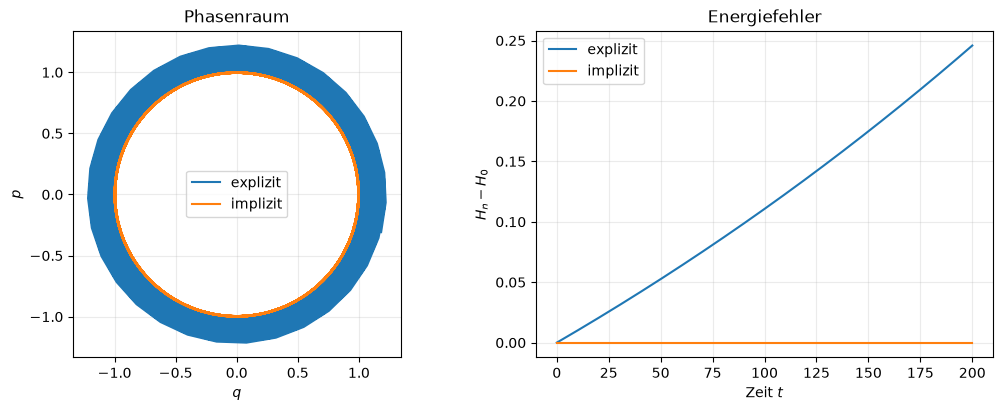

explizit : maximaler Betrag des Energiefehlers 2.459e-01
implizit : maximaler Betrag des Energiefehlers 7.161e-15


In [6]:
midpoint_methods = {
    "explizit": explicit_midpoint,
    "implizit": implicit_midpoint,
}
q0_mid, p0_mid = 1.0, 0.0
h_mid, T_mid = 0.2, 200.0
n_mid = int(round(T_mid/h_mid))
midpoint_results = {}

fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for name, method in midpoint_methods.items():
    t, q, p = simulate_midpoint(method, q0_mid, p0_mid, h_mid, n_mid)
    energy_error = 0.5*(q**2 + p**2) - 0.5*(q0_mid**2 + p0_mid**2)
    midpoint_results[name] = (t, q, p, energy_error)
    axes[0].plot(q, p, label=name)
    axes[1].plot(t, energy_error, label=name)

axes[0].set(xlabel="$q$", ylabel="$p$", title="Phasenraum")
axes[0].set_aspect("equal", adjustable="box")
axes[1].set(xlabel="Zeit $t$", ylabel="$H_n-H_0$", title="Energiefehler")
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()
plt.show()

for name, (_, _, _, energy_error) in midpoint_results.items():
    print(f"{name:9s}: maximaler Betrag des Energiefehlers "
          f"{np.max(np.abs(energy_error)):.3e}")

**Beobachtungen:**

Die explizite Mittelpunktregel erzeugt eine langsam nach außen laufende Spirale und einen systematisch wachsenden Energiefehler. Der Flächenfaktor $1+h^4/4$ ist pro Schritt nur wenig größer als eins, wird aber über viele Schritte wiederholt multipliziert.

Die implizite Mittelpunktregel bleibt auf der Kreisbahn und erhält die Energie bis auf Rundungsfehler. Für den harmonischen Oszillator ist ihre Update-Matrix nicht nur symplektisch, sondern auch orthogonal. Diese Orthogonalität erhält die quadratische Energie exakt. Symplektizität allein garantiert für eine allgemeine Hamiltonfunktion dagegen keine exakte Erhaltung des ursprünglichen Hamiltonians.